# **Healthcare Engagement to Healthcare Costs Among Adults with History of Substance Use**

The Medical Expidenture Panel Survey is a nationally represented survey of the U.S. civilian noninstitutionalized population that follows households across multiple interview rounds to collect detailed info on health status, medical conditions, insurance, healthcare use, and spending. Since it follows families over the years, the MEPs is an excellents source to measure how one year's healthcare costs compare to the next.

We wanted to focus on adults who use tobacco or other substances because these populations face elevated risks of chronic disease and therefore may have higher healthcare costs. Prior spending and existing health conditions are obvious predictors of future spending, but we want to investigate if a person's engagement with the health system— like attending routine checkups or delaying care— adds predictive value beyond those.

In [2]:
import numpy as np
import pandas as pd

## **About the Datasets**

In [3]:
# MEPS HC-257: MEPS Panel 28 Longitudinal Data File: https://meps.ahrq.gov/mepsweb/data_stats/download_data_files_detail.jsp?cboPufNumber=HC-257&prfricon=yes&utm_source=chatgpt.com
    # each row is a unique person
    # key = dupersid — a primary unique person-level identifier
main_df = pd.read_stata('main.dta')

# ----------------

# 2023 Medical Conditions File: https://meps.ahrq.gov/mepsweb/data_stats/download_data_files_results.jsp?cboDataYear=All&cboDataTypeY=1%2CHousehold+Full+Year+File&buttonYearandDataType=Search&cboPufNumber=All&SearchTitle=Medical+Conditions
    # each row is a unique personXcondition combo - each row is NOT a unique person
    # key = dupersid — a primary unique person-level identifier
conditions_df = pd.read_stata('conditions.dta') 

## **Cleaning and Setting Up the Merged Dataset**

In [4]:
# Helper fxs for cleaning MEPS labeled values

def code(s):
    """Leading numeric code from a MEPS value."""
    return pd.to_numeric(
        s.astype('string').str.extract(r'^\s*(-?\d+(?:\.\d+)?)')[0], errors='coerce'
    )

def num(s):
    """Numeric variable; MEPS negative missing codes -> NaN."""
    x = code(s)
    return x.where(x >= 0)

def yesno(s):
    """MEPS 1 = Yes, 2 = No -> 1/0; missing codes -> NaN."""
    return code(s).map({1: 1.0, 2: 0.0})

def label(s):
    """Categorical variable as its text label (code stripped); missing codes -> NaN."""
    txt = s.astype('string').str.strip()
    lab = txt.str.replace(r'^-?\d+(?:\.\d+)?\s*', '', regex=True)
    lab = lab.where(lab.str.len() > 0, txt)
    return lab.where(code(s) >= 0).astype('category')


>#### Identify People With Substance Use Disorders (SUDs), like Smoking!

In [5]:
# Substance use condition flag from the 2023 conditions file

cond = conditions_df.copy()
cond['DUPERSID'] = cond['DUPERSID'].astype(str).str.strip() # DUPERSID is the unique key to identify each human 




# There's 4 columns that store a personXcondition's first, second (if applicable), third (if applicable), and fourth (if applicable) CCSR- category
    # CCSR- categories are an organized way to turn raw medical codes into nice categories
    # one raw medical code can be associated with multipel categories, hence we have 4 columns to check through to see if there's any mention of substance use stuff
ccsr_cols = ['CCSR1X', 'CCSR2X', 'CCSR3X', 'CCSR4X']




clean = lambda c: c.astype(str).str.strip().str.upper()

# For each condition row, is it related to substance use? (SUD = substance uce disorder)
is_sud = (
    
    # The ICD codes "F10" through "F19" are codes associated with substance disorders...
    clean(cond['ICD10CDX']).str.match(r'^F1\d$') 

    # ...and also...

    # ...The CCSR categories MBD017–MBD019 are associated with Alcohol, Opioids, and Cannabis 
    # and MBD020–MBD025 with Sedatives, Stimulants, and Other Substances.
    | cond[ccsr_cols].apply(lambda c: clean(c).str.match(r'^MBD0(1[7-9]|2[0-5])$')).any(axis=1))


sud_ids = set(cond.loc[is_sud, 'DUPERSID'])

In [6]:
# Build the cleaned person level dataframe
raw = main_df.copy()
raw['DUPERSID'] = raw['DUPERSID'].astype(str).str.strip()

df = pd.DataFrame({'dupersid': raw['DUPERSID']})

>#### Rename Column

In [7]:
# --- Outcome (2024) ---
df['tot_exp_y2']     = num(raw['TOTEXPY2']) # 2024 spending
df['log_tot_exp_y2'] = np.log1p(df['tot_exp_y2']) # 2024 spending LOG TRANSFORMED because it's heaaaviiilllyyyyy skewed otherwise






# --- A. Demographics (2023) ---
df['age']         = num(raw['AGEY1X'])
df['sex']         = label(raw['SEX'])
df['race_eth']    = label(raw['RACETHX'])
df['poverty_cat'] = label(raw['POVCATY1'])
df['insurance']   = label(raw['INSCOVY1'])
df['region']      = label(raw['REGIONY1'])

# --- B. Prior spending & utilization (2023) ---
df['tot_exp_y1']       = num(raw['TOTEXPY1'])
df['er_visits_y1']     = num(raw['ERTOTY1'])
df['ip_discharges_y1'] = num(raw['IPDISY1'])
df['ob_visits_y1']     = num(raw['OBTOTVY1'])
df['rx_fills_y1']      = num(raw['RXTOTY1'])






# --- C. Medical history (2023) ---
dx_vars = {
    'dx_hibp': 'HIBPDXY1', 'dx_chd': 'CHDDXY1', 'dx_angina': 'ANGIDXY1',
    'dx_mi': 'MIDXY1', 'dx_oth_heart': 'OHRTDXY1', 'dx_stroke': 'STRKDXY1',
    'dx_emphysema': 'EMPHDXY1', 'dx_chol': 'CHOLDXY1', 'dx_cancer': 'CANCERY1',
    'dx_diabetes': 'DIABDXY1_M18', 'dx_arthritis': 'ARTHDXY1', 'dx_asthma': 'ASTHDXY1',
}
for new, old in dx_vars.items():
    df[new] = yesno(raw[old])
df['n_chronic'] = df[list(dx_vars)].sum(axis=1)        # missing dx counted as 0


df['self_rated_health'] = num(raw['RTHLTH2'])          # 1 = Excellent ... 5 = Poor
df['self_rated_mental'] = num(raw['MNHLTH2'])          # 1 = Excellent ... 5 = Poor
df['any_limitation']    = yesno(raw['ANYLMIY1'])









# --- D. Engagement & access (2023, Round 2) ---
df['has_usual_source']  = yesno(raw['HAVEUS2'])
df['routine_checkup']   = yesno(raw['ADRTCR2'])
df['delayed_care_cost'] = yesno(raw['DLAYCA2'])
df['unafford_care']     = yesno(raw['AFRDCA2'])
df['covid_vax_ever']    = yesno(raw['COVAXEVR1'])









# --- Substance-use definition ---
df['smoker_y1']      = (code(raw['ADSMOK2']) == 1).astype(int)   # SAQ nonresponse -> 0
df['sud_dx']         = df['dupersid'].isin(sud_ids).astype(int)
df['substance_user'] = ((df['smoker_y1'] == 1) | (df['sud_dx'] == 1)).astype(int)






# filter for people over 18 AND have a total medical expensive != 0 in 2024
adults      = df[(df['age'] >= 18) & df['tot_exp_y2'].notna()].reset_index(drop=True) 

analytic_df = adults[adults['substance_user'] == 1].reset_index(drop=True)

/opt/miniconda3/envs/ds6021/lib/python3.12/site-packages/pandas/core/arrays/masked.py:788: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs2, **kwargs)


In [ ]:
"""
analytic_df.to_csv('conditions_cost_analytics.csv', index=False) # save as csv to this folder
# FINAL DATASET
    # Each row is a unique person (DUPERSID)...
    # ...AKA, a U.S. civilian noninstitutionalized who has a substance use disorder
"""

---
---
---

## **Summary Stats**

In [12]:

# =============================================================
# Variable blocks (for summary tables now, modeling later)
# =============================================================
OUTCOME = 'log_tot_exp_y2'
BLOCKS = {
    'A_demographics': ['age', 'sex', 'race_eth', 'poverty_cat', 'insurance', 'region'],
    'B_prior_use':    ['tot_exp_y1', 'er_visits_y1', 'ip_discharges_y1', 'ob_visits_y1', 'rx_fills_y1'],
    'C_medical':      ['n_chronic', 'self_rated_health', 'self_rated_mental', 'any_limitation', 'sud_dx'],
    'D_engagement':   ['has_usual_source', 'routine_checkup', 'delayed_care_cost',
                       'unafford_care', 'covid_vax_ever'],
}

# =============================================================
# 6. Sanity checks
# =============================================================
print(f"All adults: {len(adults)} | Analytic sample: {len(analytic_df)}")
print(analytic_df[['smoker_y1', 'sud_dx']].sum())

All adults: 7079 | Analytic sample: 585
smoker_y1    570
sud_dx        23
dtype: int64


In [16]:
spend = analytic_df[['tot_exp_y1', 'tot_exp_y2']].rename(
    columns={'tot_exp_y1': '2023 spending', 'tot_exp_y2': '2024 spending'})

# Core summary table (dollars)
summary = spend.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T
summary['share_zero'] = (spend == 0).mean().round(3)
summary['total_$'] = spend.sum()
print(summary.round(0).to_string())

# How concentrated is spending? Share of total spending from the top 10% and top 1%
for col in spend:
    s = spend[col].sort_values(ascending=False)
    top10 = s.head(int(len(s) * 0.10)).sum() / s.sum()
    top1 = s.head(int(len(s) * 0.01)).sum() / s.sum()
    print(f"{col}: top 10% account for {top10:.0%} of spending, top 1% for {top1:.0%}")

# Year-to-year persistence
print(f"\nCorrelation of 2023 and 2024 spending (raw $): {spend.corr().iloc[0, 1]:.2f}")
print(f"Correlation of 2023 and 2024 spending (log):   {np.log1p(spend).corr().iloc[0, 1]:.2f}")

               count     mean      std  min    25%     50%      75%      90%       99%       max  share_zero  total_$
2023 spending  585.0  11423.0  26711.0  0.0  499.0  2942.0  10996.0  25951.0  139988.0  275269.0         0.0  6682447
2024 spending  585.0  13280.0  42897.0  0.0  525.0  3570.0  11670.0  30140.0  121799.0  847517.0         0.0  7768578
2023 spending: top 10% account for 61% of spending, top 1% for 16%
2024 spending: top 10% account for 61% of spending, top 1% for 23%

Correlation of 2023 and 2024 spending (raw $): 0.62
Correlation of 2023 and 2024 spending (log):   0.66


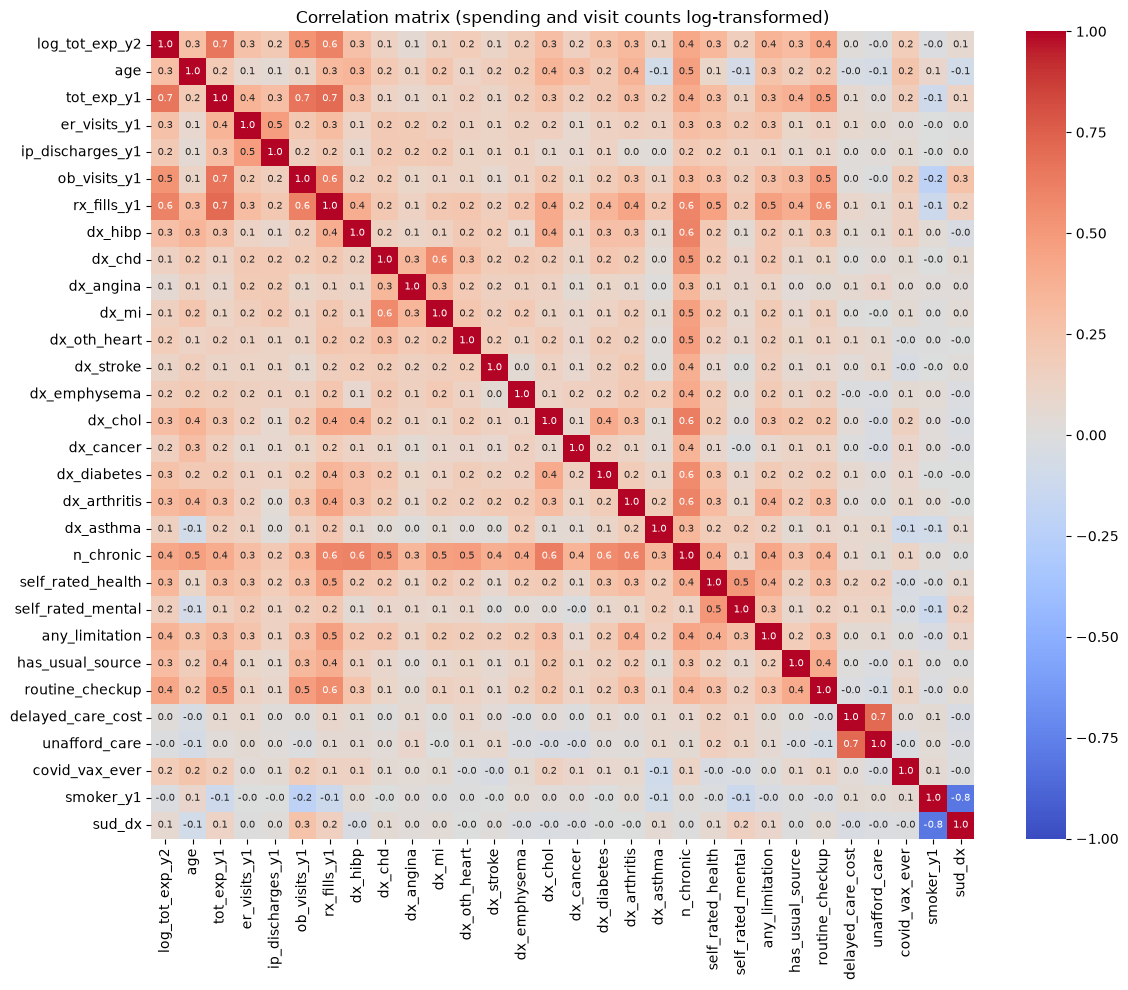

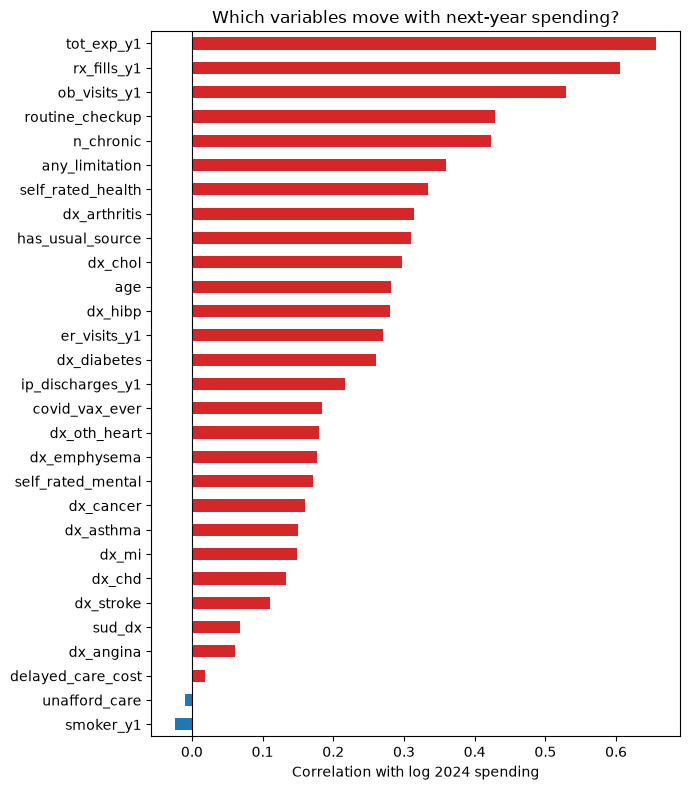

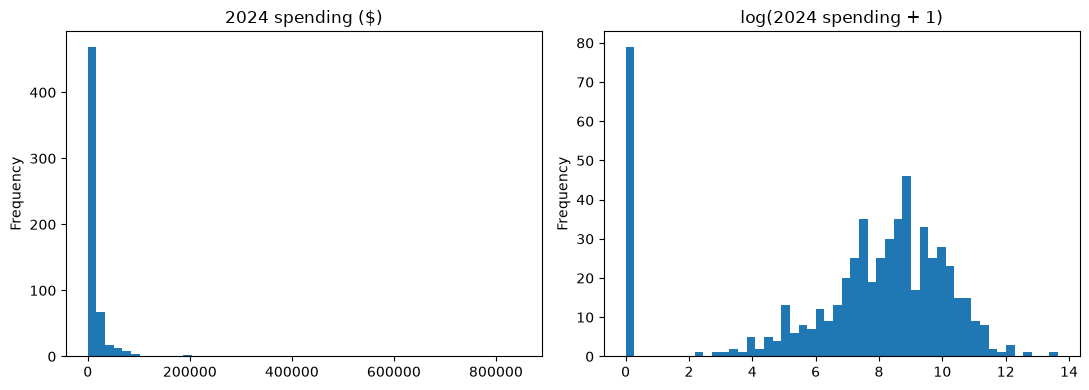

Share with $0 spending in 2024: 13.5%


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Numeric and 0/1 variables only (categoricals like race/region aren't correlated directly)
eda = analytic_df.select_dtypes(include='number').drop(columns=['substance_user'])

# Log the skewed spending/utilization variables so correlations aren't driven by outliers
for c in BLOCKS['B_prior_use'] + ['tot_exp_y2']:
    eda[c] = np.log1p(eda[c])
eda = eda.drop(columns='tot_exp_y2')          # keep only the log version of the outcome

# --- 1. Correlation heatmap ---
plt.figure(figsize=(12, 10))
sns.heatmap(eda.corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Correlation matrix (spending and visit counts log-transformed)')
plt.tight_layout()
plt.show()

# --- 2. Correlation of each variable with the outcome ---
corr_y = eda.corr()['log_tot_exp_y2'].drop('log_tot_exp_y2').sort_values()
corr_y.plot(kind='barh', figsize=(7, 8), color=np.where(corr_y > 0, 'tab:red', 'tab:blue'))
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Correlation with log 2024 spending')
plt.title('Which variables move with next-year spending?')
plt.tight_layout()
plt.show()

# --- 3. Outcome distribution: raw vs. log ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
analytic_df['tot_exp_y2'].plot(kind='hist', bins=50, ax=axes[0], title='2024 spending ($)')
analytic_df['log_tot_exp_y2'].plot(kind='hist', bins=50, ax=axes[1], title='log(2024 spending + 1)')
plt.tight_layout()
plt.show()

print(f"Share with $0 spending in 2024: {(analytic_df['tot_exp_y2'] == 0).mean():.1%}")

---
---
---

## **Model 1: Ridge Regression**

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Can we predict the log of next year's spending using ALL THE VARS

X = analytic_df[BLOCKS['A_demographics'] + BLOCKS['B_prior_use'] +
                BLOCKS['C_medical'] + BLOCKS['D_engagement']].copy()
y = analytic_df['log_tot_exp_y2']

# Basic cleanup: log prior spending, fill missing values, turn categories into dummies
X['tot_exp_y1'] = np.log1p(X['tot_exp_y1'])
X = pd.get_dummies(X, drop_first=True, dtype=float)
X = X.fillna(X.median())

# Split: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model 1: without engagement variables
engagement = BLOCKS['D_engagement']
model1 = LinearRegression().fit(X_train.drop(columns=engagement), y_train)
r2_1 = r2_score(y_test, model1.predict(X_test.drop(columns=engagement)))

# Model 2: with engagement variables
model2 = LinearRegression().fit(X_train, y_train)
r2_2 = r2_score(y_test, model2.predict(X_test))

print(f"Test R² without engagement: {r2_1:.3f}")
print(f"Test R² with engagement:    {r2_2:.3f}")

Test R² without engagement: 0.439
Test R² with engagement:    0.436
